2. Preview Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import statsmodels.api as sm
from scipy import stats

# Upload dataset CSV
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset berhasil dibaca!")
print("Ukuran dataset:", df.shape)

display(df.head())

Saving SahamMNCBank.csv to SahamMNCBank.csv
Dataset berhasil dibaca!
Ukuran dataset: (1857, 13)


,Date,Open,High,Low,Close,Change,Change(%),Ratio(%),Volume,Value(T),Interval_High_Open,Interval_Open_From_LastDay,Interval_Open_From_LastDay(%)
0,8/30/2021,438,462,434,450,Rise,14,3.21,"5,444,095","244,258,988",24,2,0.458715596
1,8/27/2021,432,462,410,436,Unchnaged,0,0.00,"5,179,738","229,353,044",30,-4,-0.917431193
2,8/26/2021,470,472,436,436,Lower limit,32,6.83,"5,266,867","239,652,022",2,2,0.427350427
3,8/25/2021,476,500,452,468,Unchnaged,0,0.00,"14,433,942","691,292,155",24,8,1.709401709
4,8/24/2021,424,494,408,468,Rise,48,11.42,"14,218,161","640,991,240",70,4,0.952380952


5. Statistik Deskriptif

In [ ]:
# Mengubah kolom Date menjadi format tanggal
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Membersihkan kolom numerik yang menggunakan koma
kolom_angka = ["Volume", "Value(T)"]

for kolom in kolom_angka:
    df[kolom] = pd.to_numeric(
        df[kolom].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

# Mengurutkan data dari tanggal terlama ke terbaru
df = df.sort_values("Date").reset_index(drop=True)

# Memeriksa informasi dataset
print("Informasi Dataset:")
df.info()

print("\nJumlah Nilai Kosong:")
print(df.isnull().sum())

# Statistik deskriptif untuk variabel numerik
print("\nStatistik Deskriptif:")
display(df.describe())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1857 entries, 0 to 1856
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Date                           1857 non-null   datetime64[ns]
 1   Open                           1857 non-null   int64         
 2   High                           1857 non-null   int64         
 3   Low                            1857 non-null   int64         
 4   Close                          1857 non-null   int64         
 5   Change                         1841 non-null   object        
 6   Change(%)                      1857 non-null   int64         
 7   Ratio(%)                       1857 non-null   float64       
 8   Volume                         1857 non-null   int64         
 9   Value(T)                       1857 non-null   int64         
 10  Interval_High_Open             1857 non-null   int64         
 11

,Date,Open,High,Low,Close,Change(%),Ratio(%),Volume,Value(T),Interval_High_Open,Interval_Open_From_LastDay
count,1857,1857.000000,1857.000000,1857.000000,1857.000000,1857.000000,1857.000000,1.857000e+03,1.857000e+03,1857.000000,1857.00000
mean,2017-10-29 06:05:14.054927104,78.060312,80.190630,76.561120,78.022079,1.653204,1.402003,4.963132e+05,1.176308e+07,2.130318,0.28056
min,2014-01-02 00:00:00,50.000000,50.000000,50.000000,50.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,-30.00000
25%,2015-11-26 00:00:00,50.000000,50.000000,50.000000,50.000000,0.000000,0.000000,2.475000e+03,1.386600e+04,0.000000,0.00000
50%,2017-10-30 00:00:00,61.000000,63.000000,60.000000,61.000000,0.000000,0.000000,2.805500e+04,1.895000e+05,1.000000,0.00000
75%,2019-10-01 00:00:00,80.000000,82.000000,78.000000,80.000000,1.000000,1.920000,1.116300e+05,8.192670e+05,2.000000,0.00000
max,2021-08-30 00:00:00,620.000000,630.000000,570.000000,610.000000,90.000000,35.000000,3.157779e+07,1.125874e+09,105.000000,137.00000
std,NaN,59.254470,63.448843,56.755437,59.800558,5.600217,2.932686,2.188012e+06,7.058743e+07,6.505322,3.76912


In [ ]:
#Jumlah Data Setelah Pembersihan
kolom = ["Date", "Open", "High", "Low", "Close"]

data = df[kolom].copy()

data["Date"] = pd.to_datetime(
    data["Date"],
    errors="coerce"
)

for kolom_harga in ["Open", "High", "Low", "Close"]:
    data[kolom_harga] = pd.to_numeric(
        data[kolom_harga],
        errors="coerce"
    )

data = data.dropna(
    subset=["Date", "Open", "High", "Low", "Close"]
)

data = data.drop_duplicates(subset=["Date"])

data = data.sort_values("Date").reset_index(drop=True)

display(data.head())
print("Jumlah data setelah pembersihan:", len(data))

,Date,Open,High,Low,Close
0,2014-01-02,137,147,136,143
1,2014-01-03,140,143,137,139
2,2014-01-06,135,140,135,137
3,2014-01-07,137,137,135,136
4,2014-01-08,136,140,134,138


Jumlah data setelah pembersihan: 1857


In [ ]:
#Tabel statistik deskriptif (setelah pembersihan)
display(
    data[["Open", "High", "Low", "Close"]].describe()
)

,Open,High,Low,Close
count,1857.000000,1857.000000,1857.000000,1857.000000
mean,78.060312,80.190630,76.561120,78.022079
std,59.254470,63.448843,56.755437,59.800558
min,50.000000,50.000000,50.000000,50.000000
25%,50.000000,50.000000,50.000000,50.000000
50%,61.000000,63.000000,60.000000,61.000000
75%,80.000000,82.000000,78.000000,80.000000
max,620.000000,630.000000,570.000000,610.000000


6. Fitting Model (Regresi Linear Sederhana dan Regresi Linear Berganda)

In [ ]:
from sklearn.model_selection import train_test_split

X1 = data[["Open"]]
y = data["Close"]

X1_train, X1_test, y_train, y_test = train_test_split(
    X1,
    y,
    test_size=0.2,
    shuffle=False
)

print("Jumlah data latih:", len(X1_train))
print("Jumlah data uji:", len(X1_test))

Jumlah data latih: 1485
Jumlah data uji: 372


In [ ]:
#Regresi linear sederhana
model_sederhana = LinearRegression()

model_sederhana.fit(X1_train, y_train)

print("Intercept:", model_sederhana.intercept_)
print("Koefisien:", model_sederhana.coef_[0])

Intercept: 0.28350362650920147
Koefisien: 0.9918734624531732


In [ ]:
#Prediksi regresi linear sederhana
y_pred_sederhana = model_sederhana.predict(X1_test)

hasil_sederhana = pd.DataFrame({
    "Close Aktual": y_test.values,
    "Close Prediksi": y_pred_sederhana
})

display(hasil_sederhana.head(10))

,Close Aktual,Close Prediksi
0,50,49.877177
1,50,49.877177
2,50,49.877177
3,50,49.877177
4,50,49.877177
5,50,49.877177
6,50,49.877177
7,50,49.877177
8,50,49.877177
9,50,49.877177


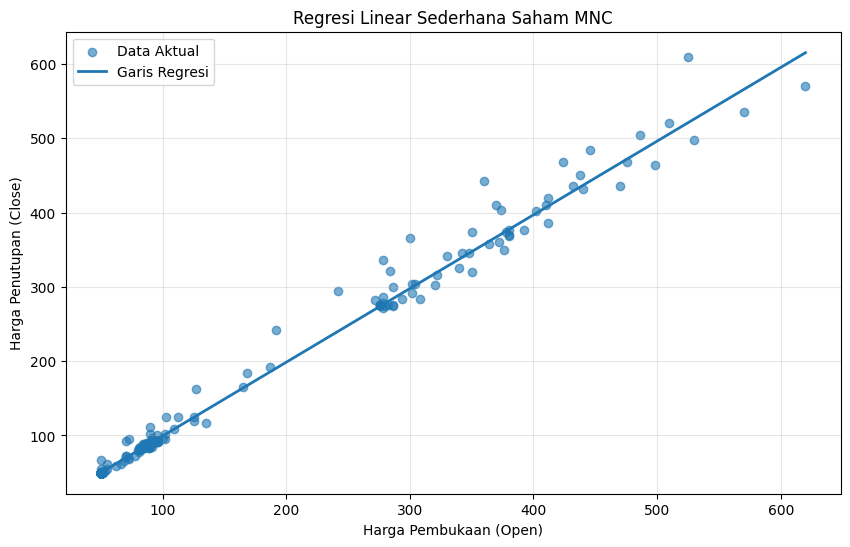

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Membuat visualisasi regresi linear sederhana
plt.figure(figsize=(10, 6))

plt.scatter(
    X1_test["Open"],
    y_test,
    alpha=0.6,
    label="Data Aktual"
)

# Mengurutkan nilai X agar garis tidak berantakan
urutan = np.argsort(X1_test["Open"].values)

plt.plot(
    X1_test["Open"].values[urutan],
    y_pred_sederhana[urutan],
    label="Garis Regresi",
    linewidth=2
)

plt.title("Regresi Linear Sederhana Saham MNC")
plt.xlabel("Harga Pembukaan (Open)")
plt.ylabel("Harga Penutupan (Close)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
#Regresi linear berganda
X2 = data[["Open", "High", "Low"]]

X2_train, X2_test, y_train, y_test = train_test_split(
    X2,
    y,
    test_size=0.2,
    shuffle=False
)

model_berganda = LinearRegression()

model_berganda.fit(X2_train, y_train)

print("Intercept:", model_berganda.intercept_)

for nama, koef in zip(
    X2.columns,
    model_berganda.coef_
):
    print(f"Koefisien {nama}: {koef}")

Intercept: -0.219084291093381
Koefisien Open: -0.3453541820768856
Koefisien High: 0.5026689725532949
Koefisien Low: 0.8466160638560245


In [ ]:
#Prediksi regresi linear berganda
y_pred_berganda = model_berganda.predict(X2_test)

hasil_berganda = pd.DataFrame({
    "Close Aktual": y_test.values,
    "Close Prediksi": y_pred_berganda
})

display(hasil_berganda.head(10))

,Close Aktual,Close Prediksi
0,50,49.977458
1,50,49.977458
2,50,49.977458
3,50,49.977458
4,50,49.977458
5,50,49.977458
6,50,49.977458
7,50,49.977458
8,50,49.977458
9,50,49.977458


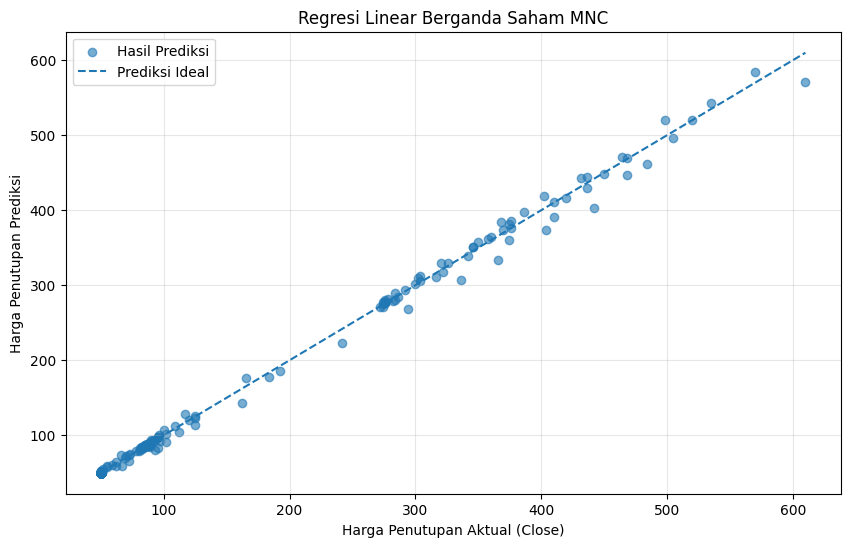

In [ ]:
#Visualisasi Regresi Linear Berganda
plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred_berganda,
    alpha=0.6,
    label="Hasil Prediksi"
)

# Garis prediksi ideal
nilai_min = min(y_test.min(), y_pred_berganda.min())
nilai_max = max(y_test.max(), y_pred_berganda.max())

plt.plot(
    [nilai_min, nilai_max],
    [nilai_min, nilai_max],
    linestyle="--",
    label="Prediksi Ideal"
)

plt.title("Regresi Linear Berganda Saham MNC")
plt.xlabel("Harga Penutupan Aktual (Close)")
plt.ylabel("Harga Penutupan Prediksi")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

7. Menampilkan tabel MAE, RMSE, dan R2

In [ ]:
#Menghitung MAE, RMSE, dan R2
def evaluasi_model(y_aktual, y_prediksi, nama_model):
    return {
        "Model": nama_model,
        "MAE": mean_absolute_error(y_aktual, y_prediksi),
        "RMSE": np.sqrt(
            mean_squared_error(y_aktual, y_prediksi)
        ),
        "R2": r2_score(y_aktual, y_prediksi)
    }

tabel_evaluasi = pd.DataFrame([
    evaluasi_model(
        y_test,
        y_pred_sederhana,
        "Regresi Linear Sederhana"
    ),
    evaluasi_model(
        y_test,
        y_pred_berganda,
        "Regresi Linear Berganda"
    )
])

display(tabel_evaluasi.round(4))

,Model,MAE,RMSE,R2
0,Regresi Linear Sederhana,4.2378,12.0694,0.9898
1,Regresi Linear Berganda,2.1639,5.8237,0.9976


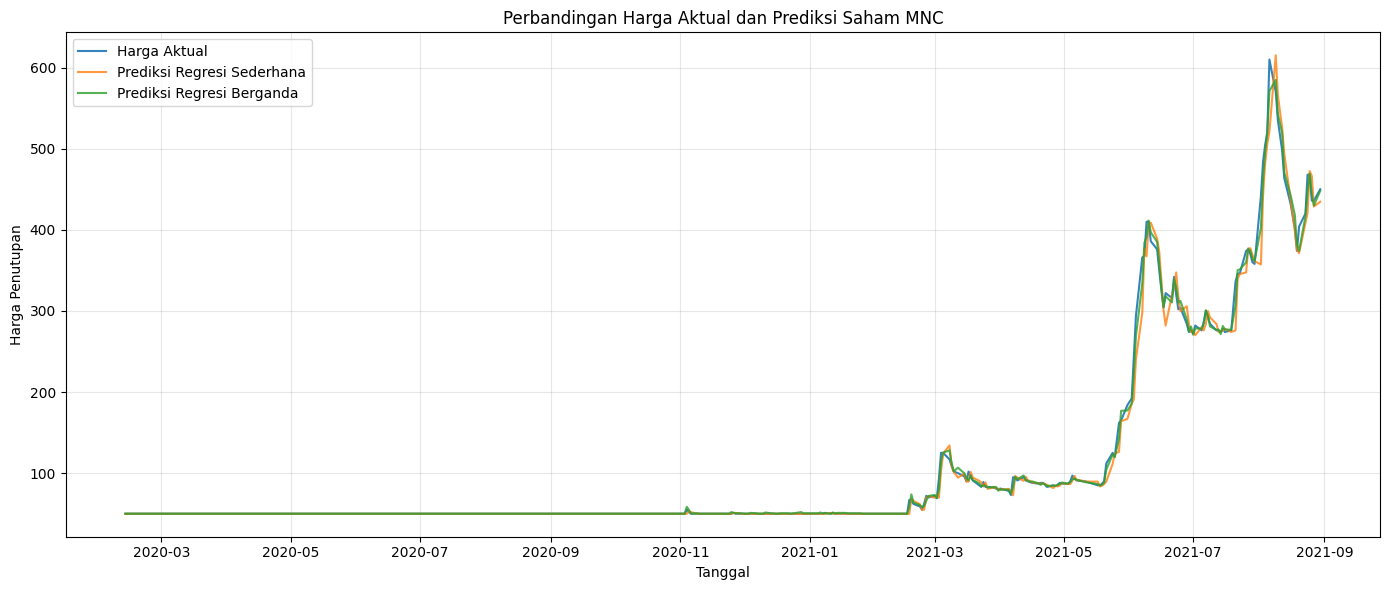

In [ ]:
#Grafik Perbandingan MAE, RMSE, dan R2
tanggal_uji = data.loc[y_test.index, "Date"]

plt.figure(figsize=(14, 6))

plt.plot(
    tanggal_uji,
    y_test.values,
    label="Harga Aktual",
    alpha=0.9
)

plt.plot(
    tanggal_uji,
    y_pred_sederhana,
    label="Prediksi Regresi Sederhana",
    alpha=0.8
)

plt.plot(
    tanggal_uji,
    y_pred_berganda,
    label="Prediksi Regresi Berganda",
    alpha=0.8
)

plt.title("Perbandingan Harga Aktual dan Prediksi Saham MNC")
plt.xlabel("Tanggal")
plt.ylabel("Harga Penutupan")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

9. Visualisasi

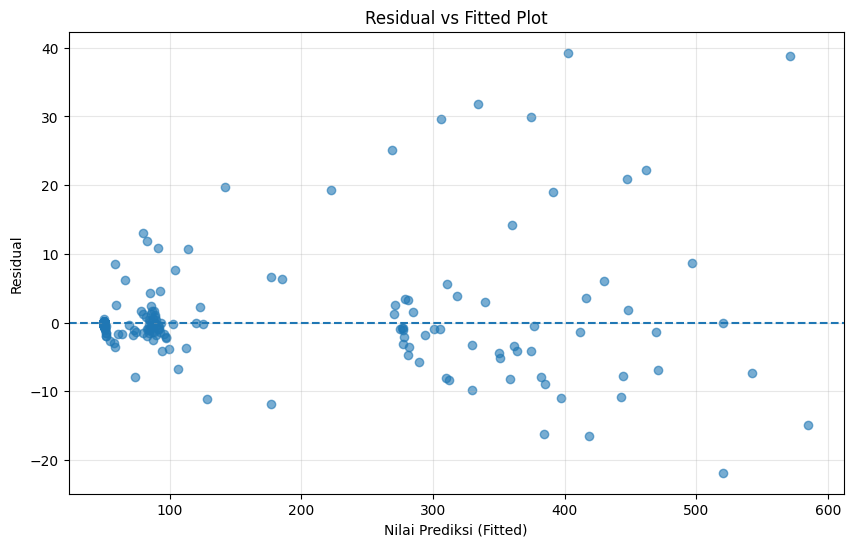

In [ ]:
#Residual vs Fitted Plot
residual = y_test.values - y_pred_berganda

plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred_berganda,
    residual,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residual vs Fitted Plot")
plt.xlabel("Nilai Prediksi (Fitted)")
plt.ylabel("Residual")
plt.grid(True, alpha=0.3)

plt.show()

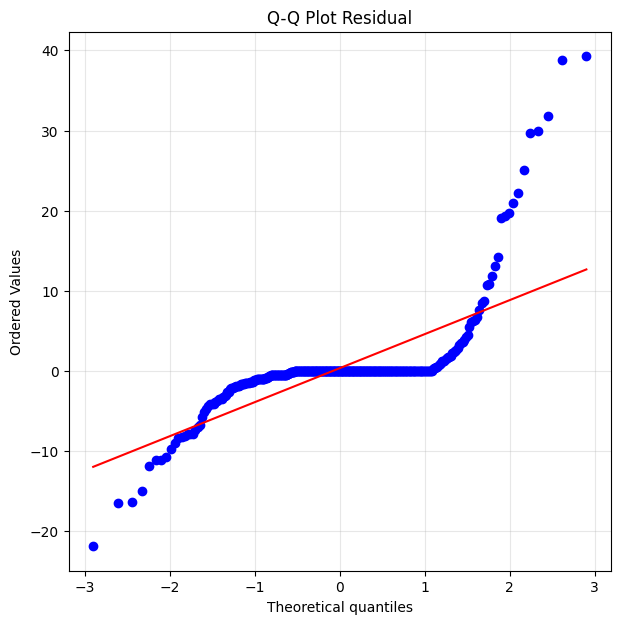

In [ ]:
#Q-Q Plot
from scipy import stats

plt.figure(figsize=(7, 7))

stats.probplot(
    residual,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot Residual")
plt.grid(True, alpha=0.3)

plt.show()

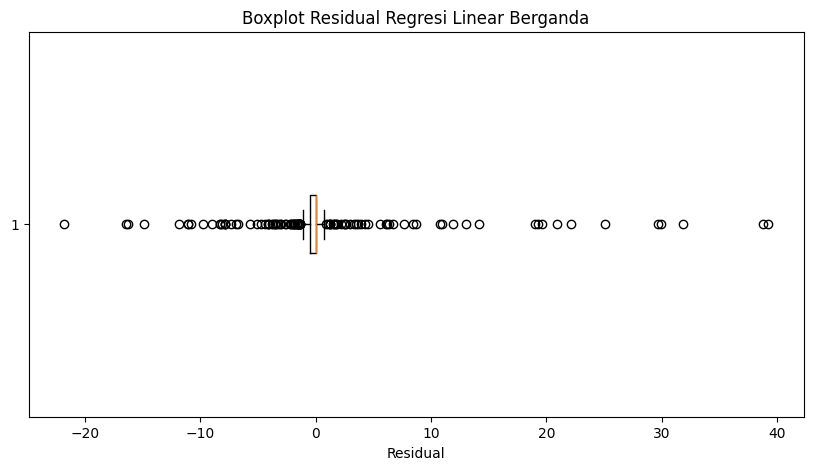

In [ ]:
#Boxplot
plt.figure(figsize=(10, 5))

plt.boxplot(
    residual,
    vert=False
)

plt.title("Boxplot Residual Regresi Linear Berganda")
plt.xlabel("Residual")

plt.show()

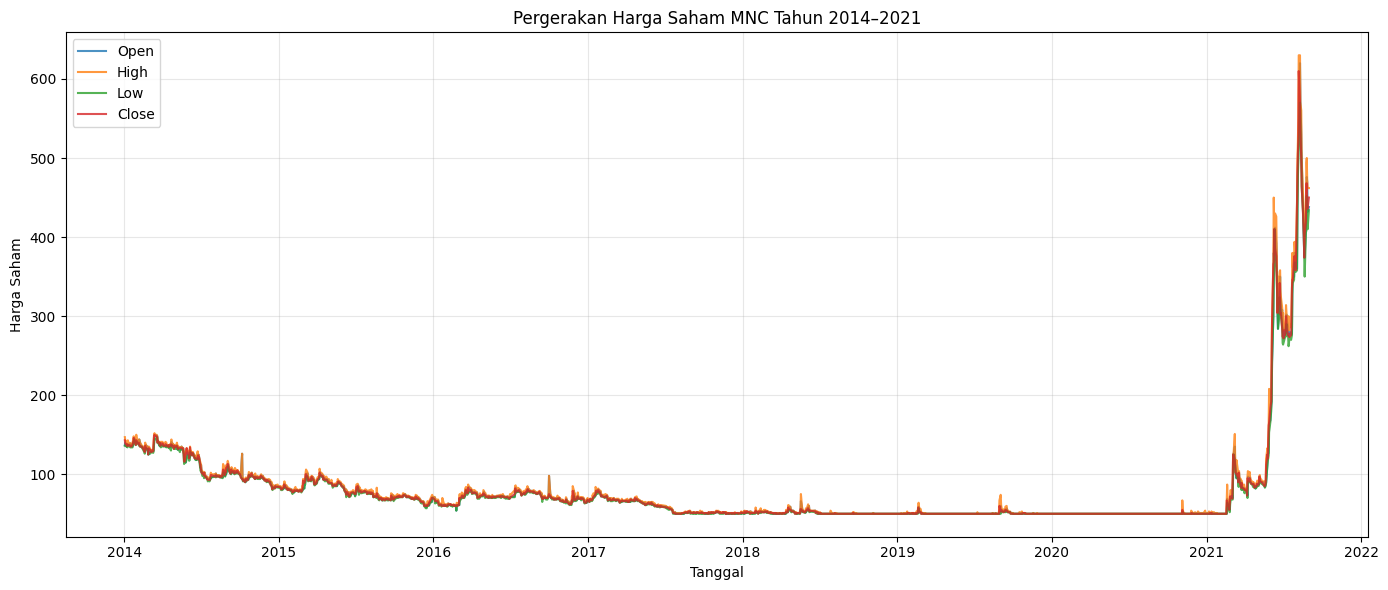

In [ ]:
#Grafik Pergerakan Harga Saham
plt.figure(figsize=(14, 6))

for kolom in ["Open", "High", "Low", "Close"]:
    plt.plot(
        data["Date"],
        data[kolom],
        label=kolom,
        alpha=0.8
    )

plt.title("Pergerakan Harga Saham MNC Tahun 2014–2021")
plt.xlabel("Tanggal")
plt.ylabel("Harga Saham")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

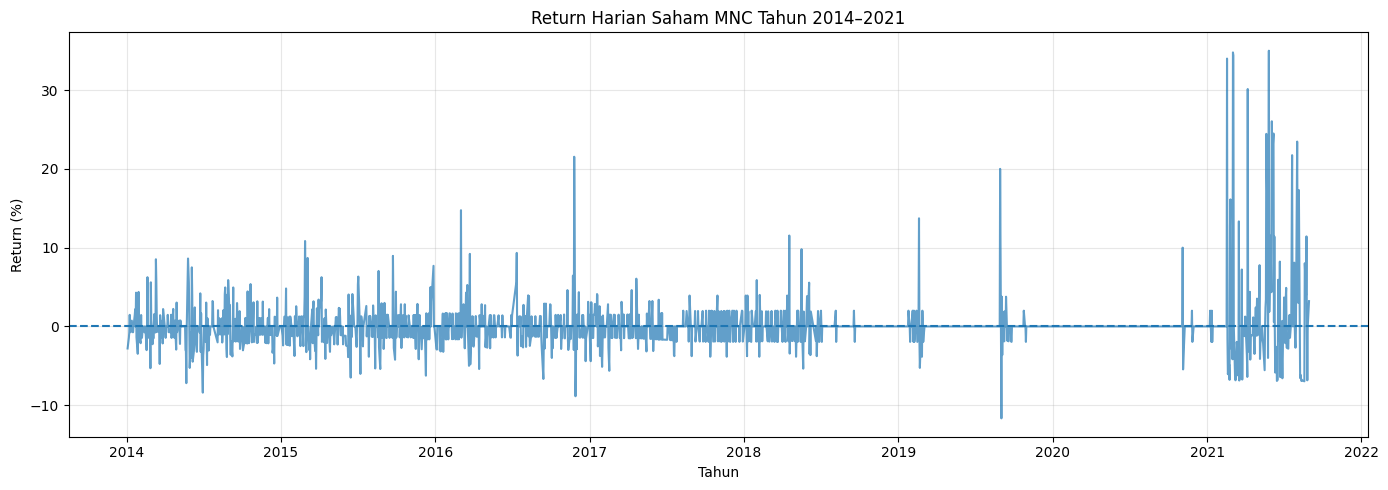

In [ ]:
#Analisis Return Saham
data["Return(%)"] = (
    data["Close"].pct_change() * 100
)

plt.figure(figsize=(14, 5))

plt.plot(
    data["Date"],
    data["Return(%)"],
    alpha=0.7
)

plt.axhline(y=0, linestyle="--")

plt.title("Return Harian Saham MNC Tahun 2014–2021")
plt.xlabel("Harian")
plt.ylabel("Return (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()